# 01. Data pipeline for Joto Mjini

This notebook runs the pipeline in `src/pipeline/` step by step and shows a quick look at each output. Each step skips work that is already done, so running the notebook again is fast. To rebuild a step from scratch, run its script with `--force`, for example `uv run python -m src.pipeline.s2_landsat --force`.

Every dataset is listed with its licence and citation in `data/SOURCES.md`.

In [1]:
import sys, os
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
os.chdir(ROOT); sys.path.insert(0, str(ROOT))
import numpy as np, pandas as pd, geopandas as gpd, matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap, BoundaryNorm
from src.config import RASTERS, PROCESSED, UTM
from src.rasterio_utils import read, read_grid, county_mask
plt.rcParams.update({"figure.dpi": 110, "font.family": "sans-serif", "axes.titlelocation": "left"})

## Step 1. Study area, wards and place names

Nairobi County comes from geoBoundaries (ADM1). The 85 wards come from geoBoundaries ADM3, which is based on the Kenya County Assembly Boundaries by B. A. Omare and G. Omare. Place names, parks and forests come from OpenStreetMap.

County area 705.3 km2; 85 wards covering 684.0 km2


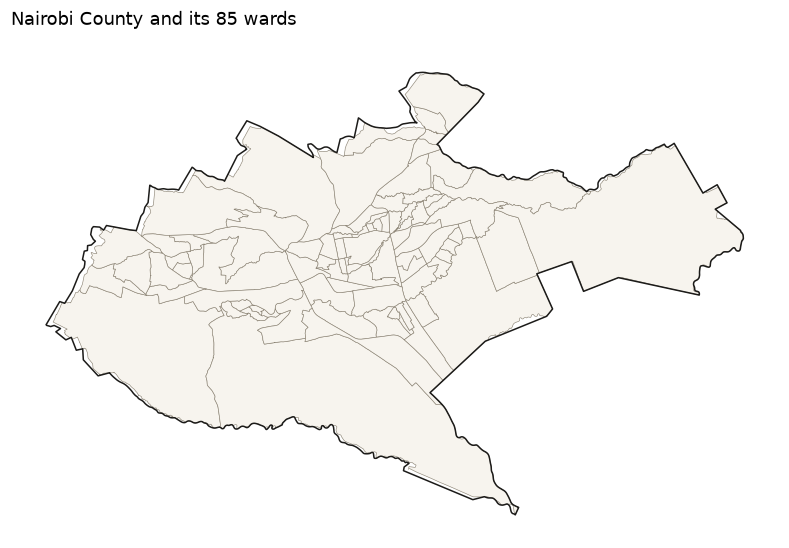

In [2]:
from src.pipeline import s1_boundaries
s1_boundaries.main()
county = gpd.read_file(PROCESSED / "nairobi_boundary.geojson").to_crs(UTM)
wards = gpd.read_file(PROCESSED / "nairobi_wards.geojson").to_crs(UTM)
print(f"County area {county.area.sum()/1e6:.1f} km2; {len(wards)} wards covering {wards.area.sum()/1e6:.1f} km2")
ax = wards.plot(facecolor="#F7F4EE", edgecolor="#8C8475", linewidth=0.4, figsize=(9, 6))
county.boundary.plot(ax=ax, color="#1C1B19", linewidth=1)
ax.set_title("Nairobi County and its 85 wards"); ax.set_axis_off()

## Step 2. Landsat surface temperature

We search every Landsat 8 and 9 scene over Nairobi since April 2013 on Microsoft Planetary Computer, mask clouds with the `qa_pixel` band, convert the surface temperature band to °C, and keep a scene as usable when at least 80 % of the county is clear. Composites are the median of usable scenes, pixel by pixel.

This is **land surface temperature**: how hot the ground, roofs and roads are, measured at about 100 m. It is different from the air temperature people feel.

In [3]:
from src.pipeline import s2_landsat, s2b_composites
cat = s2_landsat.main()
meta = s2b_composites.main()
print(f"{len(cat)} scenes, {int(cat.usable.sum())} usable")
print("Hot season:", meta["hot_season"]["n_scenes"], "scenes from", meta["hot_season"]["first_year"])
print("Cool season:", meta["cool_season"]["n_scenes"], "scenes from", meta["cool_season"]["first_year"])
print("Hottest clear day:", meta["hottest_clear_day"])

2026-11-10 13:56:39 INFO STAC search: 205 daytime items with scene cloud cover under 40%


2026-11-10 13:56:39 INFO 205 scenes already catalogued, 0 to process


2026-11-10 13:56:39 INFO Catalogue: 205 scenes, 68 usable


2026-11-10 13:56:39 INFO hot_season: 12 scenes from 2023 onward


2026-11-10 13:56:39 INFO cool_season: 4 scenes from 2018 onward


2026-11-10 13:56:39 INFO Hottest clear day: 2022-09-29, county median 46.6 C


2026-11-10 13:56:39 INFO By-year composites: {2015: 2, 2016: 2, 2017: 3, 2018: 2, 2019: 2, 2020: 3, 2021: 3, 2022: 5, 2023: 5, 2025: 2, 2026: 4}


205 scenes, 68 usable
Hot season: 12 scenes from 2023
Cool season: 4 scenes from 2018
Hottest clear day: {'scene_id': 'LC09_L2SP_168061_20220929_02_T1', 'date': '2022-09-29', 'county_median_c': 46.59}


### The scene catalogue (usable scenes)

In [4]:
cat[cat.usable][["scene_id", "datetime_nairobi", "clear_fraction_county", "lst_median_c", "lst_p10_c", "lst_p90_c"]].tail(25)

,scene_id,datetime_nairobi,clear_fraction_county,lst_median_c,lst_p10_c,lst_p90_c
117,LC09_L2SP_168061_20221015_02_T1,2022-10-15 10:43:37,0.9479,45.32,33.30,53.13
124,LC09_L2SP_168061_20230119_02_T1,2023-01-19 10:43:29,0.9952,38.27,28.55,46.45
125,LC09_L2SP_168061_20230204_02_T1,2023-02-04 10:43:40,0.9960,44.93,35.44,54.31
126,LC08_L2SP_168061_20230212_02_T1,2023-02-12 10:43:28,0.9952,41.18,33.98,46.44
127,LC09_L2SP_168061_20230220_02_T1,2023-02-20 10:43:32,0.9926,43.21,35.21,49.53
128,LC09_L2SP_168061_20230308_02_T1,2023-03-08 10:43:20,0.9960,45.25,37.37,50.86
135,LC09_L2SP_168061_20231002_02_T1,2023-10-02 10:43:15,0.9798,43.12,33.73,49.63
145,LC08_L2SP_168061_20240215_02_T1,2024-02-15 10:43:14,0.9765,38.09,31.12,42.48
149,LC09_L2SP_168061_20240411_02_T1,2024-04-11 10:43:07,0.8722,33.56,28.89,38.26
150,LC09_L2SP_168061_20240513_02_T1,2024-05-13 10:42:44,0.9890,32.76,28.47,38.99


### Quick look: hot-season surface temperature

Fixed colour breaks (the same breaks used on the website), so maps from different seasons can be compared directly.

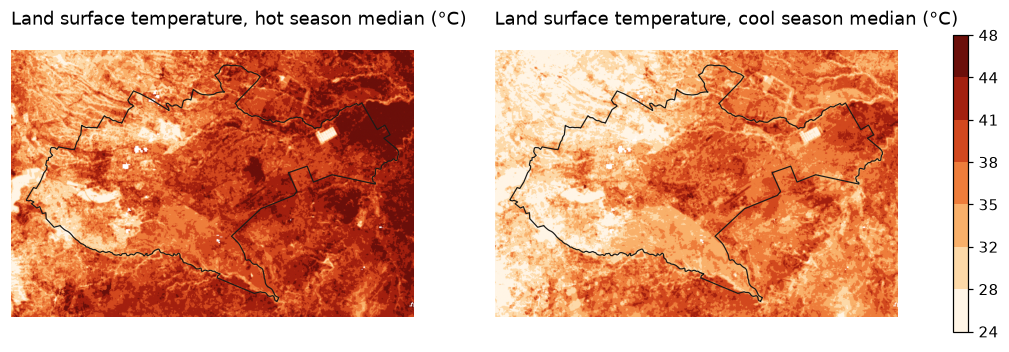

In [5]:
BREAKS = [24, 28, 32, 35, 38, 41, 44, 48]
HEAT = ["#FFF5E6", "#FDD9A8", "#F9B06A", "#EE7D3B", "#D2481E", "#A3200F", "#6B0F0A"]
cmap, norm = ListedColormap(HEAT), BoundaryNorm(BREAKS, len(HEAT))
t, w, h = read_grid()
ext = [t.c, t.c + w * t.a, t.f + h * t.e, t.f]
fig, axs = plt.subplots(1, 2, figsize=(13, 5))
for ax, name in zip(axs, ["hot_season", "cool_season"]):
    a = read(RASTERS / f"lst_{name}_median.tif")
    im = ax.imshow(a, cmap=cmap, norm=norm, extent=ext)
    county.boundary.plot(ax=ax, color="#1C1B19", linewidth=0.8)
    ax.set_title(f"Land surface temperature, {name.replace('_', ' ')} median (°C)"); ax.set_axis_off()
fig.colorbar(im, ax=axs, shrink=0.7, ticks=BREAKS)

## Step 3. Land cover, population, buildings and built-up growth

ESA WorldCover 2021 (10 m), WorldPop 2025 constrained population (100 m), Overture building footprints and GHSL built-up surface (1975 to 2025).

Share of county: {'Tree cover': '21.1%', 'Shrubland': '10.5%', 'Grassland': '30.1%', 'Cropland': '4.9%', 'Built-up': '31.7%', 'Bare': '1.0%', 'Water': '0.6%', 'Wetland': '0.0%'}
WorldPop 2025 county total on 30 m grid: 5,657,304


Buildings: 746,499


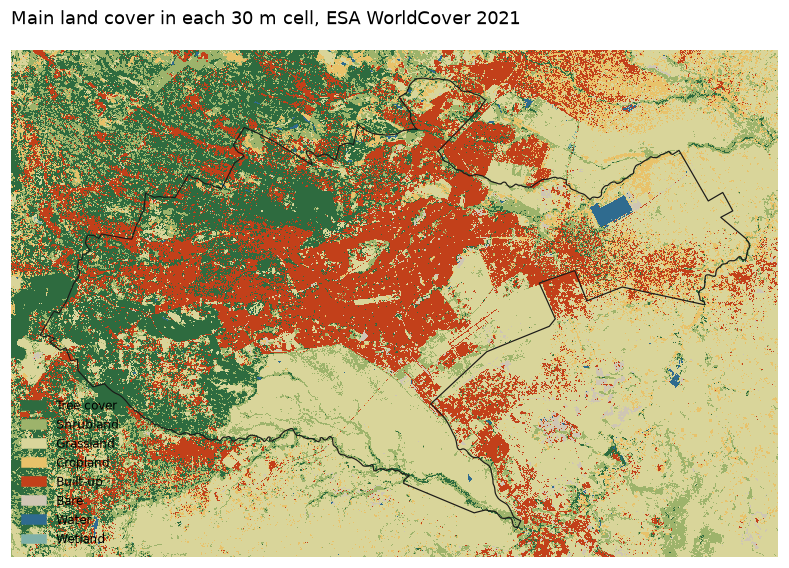

In [6]:
from src.pipeline import s3_context
s3_context.main()
wc = read(RASTERS / "worldcover_majority_30m.tif")
codes = [10, 20, 30, 40, 50, 60, 80, 90]
cols = ["#2E6B3F", "#9DB36B", "#D9D59A", "#E8C26A", "#C2401A", "#CFC6B4", "#2F6B8F", "#7FB0A8"]
names = ["Tree cover", "Shrubland", "Grassland", "Cropland", "Built-up", "Bare", "Water", "Wetland"]
lut = np.full(256, np.nan); [lut.__setitem__(c, i) for i, c in enumerate(codes)]
idx = lut[np.nan_to_num(wc, nan=0).astype(int)]
fig, ax = plt.subplots(figsize=(9, 6))
ax.imshow(idx, cmap=ListedColormap(cols), vmin=-0.5, vmax=len(codes) - 0.5, extent=ext, interpolation="nearest")
county.boundary.plot(ax=ax, color="#1C1B19", linewidth=0.8); ax.set_axis_off()
ax.set_title("Main land cover in each 30 m cell, ESA WorldCover 2021")
from matplotlib.patches import Patch
ax.legend(handles=[Patch(color=c, label=n) for c, n in zip(cols, names)], loc="lower left", fontsize=8, frameon=False)
cm = county_mask()
print("Share of county:", {n: f"{100*(wc[cm]==c).mean():.1f}%" for c, n in zip(codes, names)})
pop = read(RASTERS / "population_30m.tif"); print(f"WorldPop 2025 county total on 30 m grid: {np.nansum(pop[cm]):,.0f}")
b = pd.read_parquet(PROCESSED / "nairobi_buildings.parquet", columns=["source"]); print(f"Buildings: {len(b):,}")

## Steps 4 and 5. Daily air temperature and the El Niño index

In [7]:
from src.pipeline import s4_climate
s4_climate.main()
air = pd.read_csv(PROCESSED / "nairobi_daily_air_temp.csv", parse_dates=["date"])
roni = pd.read_csv(PROCESSED / "roni.csv").dropna()
print(air.tail(3)); print(roni.tail(6))

            date  temperature_2m_max  temperature_2m_min  temperature_2m_mean
13094 2026-11-07                25.1                15.4                 18.9
13095 2026-11-08                26.0                15.9                 20.1
13096 2026-11-09                26.9                15.9                 20.2
     year season  centre_month  roni
915  2026    MAM             4   0.0
916  2026    AMJ             5   0.5
917  2026    MJJ             6   1.0
918  2026    JJA             7   1.4
919  2026    JAS             8   1.7
920  2026    ASO             9   2.0


## Step 7 and 8. Basemap and manifest

The Protomaps basemap extract is in `site/public/data/nairobi_basemap.pmtiles`. The manifest lists every processed file.

In [8]:
from src.pipeline import manifest
manifest.main()
print((PROCESSED / "MANIFEST.md").read_text()[:1500])

# Processed data manifest

Generated 2026-11-10 13:56 (Africa/Nairobi) by `src/pipeline/manifest.py`.

| File | Size | Grid | Purpose |
|---|---|---|---|
| `data/processed/_old/comparison_areas_v1.geojson` | 15 kB |  |  |
| `data/processed/_old/nairobi_wards_geoboundaries.geojson` | 0.1 MB |  |  |
| `data/processed/buildings_lst.parquet` | 93.7 MB |  |  |
| `data/processed/comparison_areas.geojson` | 31 kB |  |  |
| `data/processed/composites_meta.json` | 3 kB |  | Which scenes and years went into each composite |
| `data/processed/kisumu/composites_meta.json` | 11 kB |  | Which scenes and years went into each composite |
| `data/processed/kisumu/kisumu_boundary.geojson` | 0.3 MB |  |  |
| `data/processed/kisumu/kisumu_boundary_with_lake.geojson` | 0.2 MB |  |  |
| `data/processed/kisumu/kisumu_buildings.parquet` | 79.0 MB |  |  |
| `data/processed/kisumu/kisumu_places.geojson` | 6.5 MB |  |  |
| `data/processed/kisumu/kisumu_wards.geojson` | 0.2 MB |  |  |
| `data/processed/kisumu/lan